In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.datasets import load_breast_cancer, make_classification

In [2]:
accidents = pd.DataFrame({
    "Weather": ["Rain","Snow","Clear","Clear","Snow","Rain","Rain","Snow","Clear","Clear"],
    "Road":    ["Bad","Average","Bad","Good","Good","Average","Good","Bad","Good","Bad"],
    "Traffic": ["High","Normal","Light","Light","Normal","Light","Normal","High","High","High"],
    "Engine":  ["No","Yes","No","Yes","No","No","No","No","Yes","Yes"],
    "Accident":["Yes","Yes","No","Yes","No","No","No","Yes","No","Yes"],
})
accidents

,Weather,Road,Traffic,Engine,Accident
0,Rain,Bad,High,No,Yes
1,Snow,Average,Normal,Yes,Yes
2,Clear,Bad,Light,No,No
3,Clear,Good,Light,Yes,Yes
4,Snow,Good,Normal,No,No
5,Rain,Average,Light,No,No
6,Rain,Good,Normal,No,No
7,Snow,Bad,High,No,Yes
8,Clear,Good,High,Yes,No
9,Clear,Bad,High,Yes,Yes


In [3]:
def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()

print("Entropy of whole dataset:", round(entropy(accidents["Accident"]), 3))   # expect 1.0
print("Gini of whole dataset:   ", round(gini(accidents["Accident"]), 3))      # expect 0.5

Entropy of whole dataset: 1.0
Gini of whole dataset:    0.5


In [4]:
def split_scores(df, attribute, target):
    n = len(df)
    weighted_entropy = weighted_gini = split_info = 0
    for value, subset in df.groupby(attribute):
        w = len(subset) / n
        weighted_entropy += w * entropy(subset[target])
        weighted_gini    += w * gini(subset[target])
        split_info       -= w * np.log2(w)
    gain = entropy(df[target]) - weighted_entropy
    return {"attribute": attribute,
            "info_gain": round(gain, 3),
            "weighted_gini": round(weighted_gini, 3),
            "gain_ratio": round(gain / split_info, 3)}

scores = pd.DataFrame([split_scores(accidents, a, "Accident")
                       for a in ["Weather", "Road", "Traffic", "Engine"]])
scores.sort_values("info_gain", ascending=False)

,attribute,info_gain,weighted_gini,gain_ratio
1,Road,0.151,0.400,0.099
2,Traffic,0.125,0.417,0.079
3,Engine,0.125,0.417,0.128
0,Weather,0.049,0.467,0.031


|--- Road_Bad <= 0.50
|   |--- Engine_No <= 0.50
|   |   |--- Traffic_High <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Traffic_High >  0.50
|   |   |   |--- class: No
|   |--- Engine_No >  0.50
|   |   |--- class: No
|--- Road_Bad >  0.50
|   |--- Traffic_High <= 0.50
|   |   |--- class: No
|   |--- Traffic_High >  0.50
|   |   |--- class: Yes



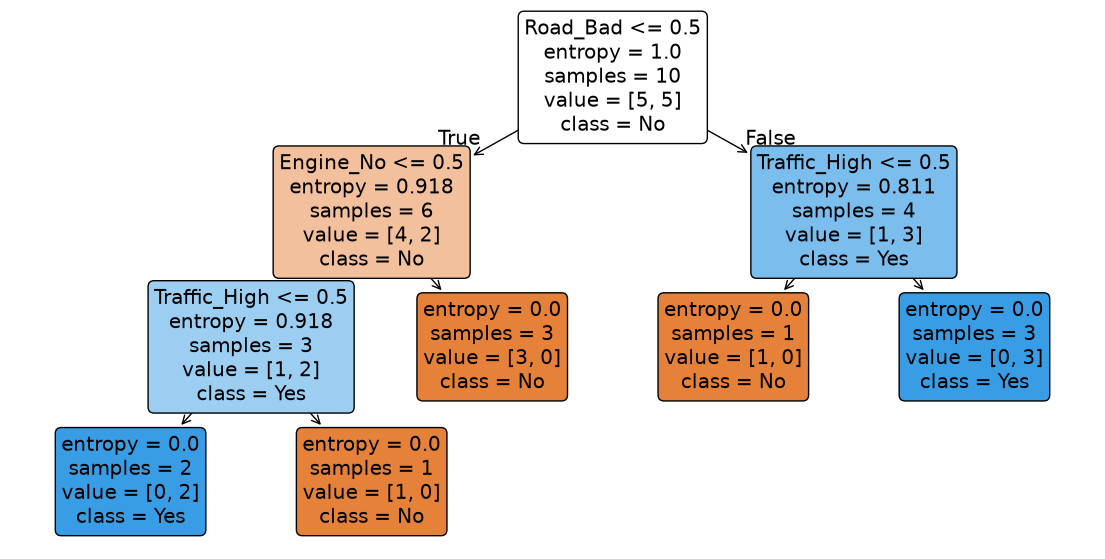

In [5]:
X_acc = pd.get_dummies(accidents.drop(columns="Accident"), dtype=int)
y_acc = accidents["Accident"]

acc_tree = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(X_acc, y_acc)
print(export_text(acc_tree, feature_names=list(X_acc.columns)))

plt.figure(figsize=(14, 7))
plot_tree(acc_tree, feature_names=X_acc.columns, class_names=acc_tree.classes_, filled=True, rounded=True)
plt.show()

In [6]:
buys = pd.DataFrame([r.split(",") for r in [
 "youth,high,no,fair,no","youth,high,no,excellent,no","middle_aged,high,no,fair,yes","senior,medium,no,fair,yes",
 "senior,low,yes,fair,yes","senior,low,yes,excellent,no","middle_aged,low,yes,excellent,yes","youth,medium,no,fair,no",
 "youth,low,yes,fair,yes","senior,medium,yes,fair,yes","youth,medium,yes,excellent,yes","middle_aged,medium,no,excellent,yes",
 "middle_aged,high,yes,fair,yes","senior,medium,no,excellent,no"]],
 columns=["age","income","student","credit","buys"])
Xb = pd.get_dummies(buys.drop(columns="buys"), dtype=int)
buys_tree = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(Xb, buys["buys"])
print(export_text(buys_tree, feature_names=list(Xb.columns)))

|--- age_middle_aged <= 0.50
|   |--- student_yes <= 0.50
|   |   |--- age_senior <= 0.50
|   |   |   |--- class: no
|   |   |--- age_senior >  0.50
|   |   |   |--- credit_excellent <= 0.50
|   |   |   |   |--- class: yes
|   |   |   |--- credit_excellent >  0.50
|   |   |   |   |--- class: no
|   |--- student_yes >  0.50
|   |   |--- credit_fair <= 0.50
|   |   |   |--- income_low <= 0.50
|   |   |   |   |--- class: yes
|   |   |   |--- income_low >  0.50
|   |   |   |   |--- class: no
|   |   |--- credit_fair >  0.50
|   |   |   |--- class: yes
|--- age_middle_aged >  0.50
|   |--- class: yes



In [7]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target            # 0 = malignant, 1 = benign
print(X.shape)
print(y.value_counts().rename(index=dict(enumerate(data.target_names))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

(569, 30)
target
benign       357
malignant    212
Name: count, dtype: int64


In [8]:
full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Train accuracy:", round(full.score(X_train, y_train), 3))
print("Test accuracy: ", round(full.score(X_test, y_test), 3))
print("Depth:", full.get_depth(), " Leaves:", full.get_n_leaves())

Train accuracy: 1.0
Test accuracy:  0.918
Depth: 6  Leaves: 16


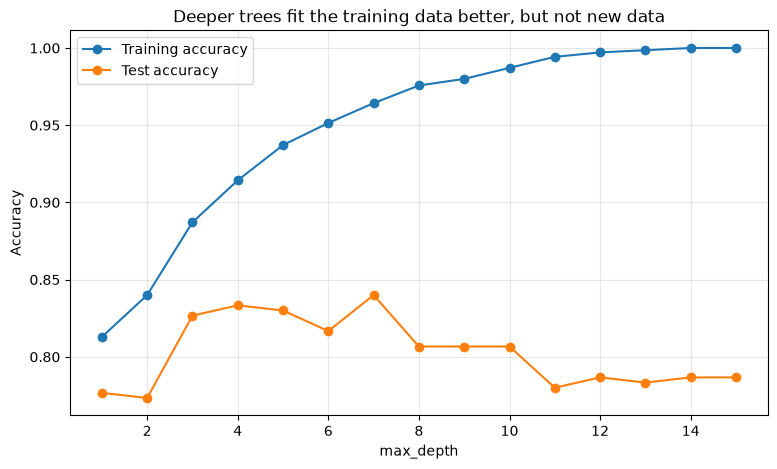

Best test depth: 7 with 0.84


In [9]:
Xn, yn = make_classification(n_samples=1000, n_features=10, n_informative=4,
                             flip_y=0.15, random_state=7)
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.3, random_state=42)

depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xn_tr, yn_tr)
    train_acc.append(m.score(Xn_tr, yn_tr))
    test_acc.append(m.score(Xn_te, yn_te))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, marker="o", label="Training accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Deeper trees fit the training data better, but not new data")
plt.show()
print("Best test depth:", depths[int(np.argmax(test_acc))], "with", round(max(test_acc), 3))

In [10]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 3, 4, 5, 6, 8, None],
                "min_samples_leaf": [1, 5, 10, 20]},
    cv=5, scoring="accuracy")
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)
print("Cross-validated accuracy:", round(grid.best_score_, 3))
pre = grid.best_estimator_
print("Test accuracy:", round(pre.score(X_test, y_test), 3),
      " Depth:", pre.get_depth(), " Leaves:", pre.get_n_leaves())

Best settings: {'max_depth': 3, 'min_samples_leaf': 1}
Cross-validated accuracy: 0.942
Test accuracy: 0.924  Depth: 3  Leaves: 7


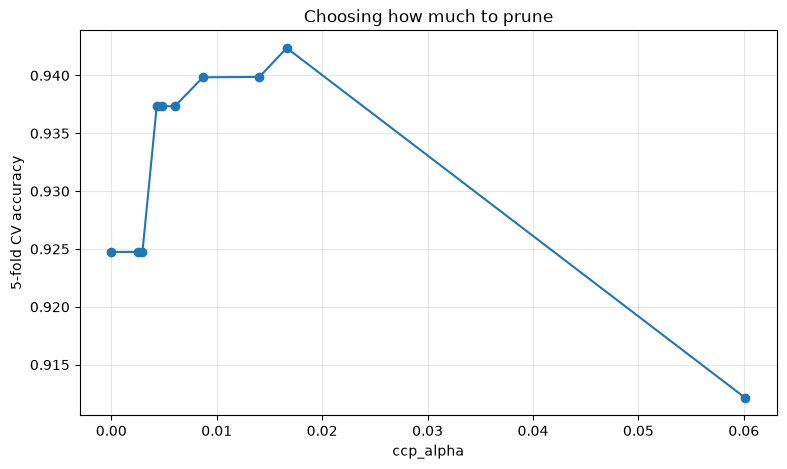

Best alpha: 0.0166
Test accuracy: 0.918  Depth: 2  Leaves: 3


In [11]:
from sklearn.model_selection import cross_val_score
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]            # the last alpha prunes everything down to the root

cv_scores = [cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a),
                             X_train, y_train, cv=5).mean() for a in alphas]
best_alpha = alphas[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(alphas, cv_scores, marker="o")
plt.xlabel("ccp_alpha"); plt.ylabel("5-fold CV accuracy"); plt.grid(alpha=0.3)
plt.title("Choosing how much to prune"); plt.show()

post = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
print("Best alpha:", round(best_alpha, 4))
print("Test accuracy:", round(post.score(X_test, y_test), 3),
      " Depth:", post.get_depth(), " Leaves:", post.get_n_leaves())

,model,test_accuracy,depth,leaves
0,Full tree,0.918,6,16
1,Pre-pruned (grid search),0.924,3,7
2,Post-pruned (ccp_alpha),0.918,2,3


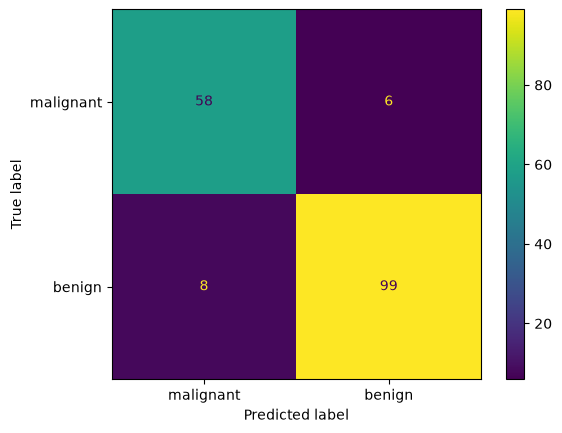

              precision    recall  f1-score   support

   malignant       0.88      0.91      0.89        64
      benign       0.94      0.93      0.93       107

    accuracy                           0.92       171
   macro avg       0.91      0.92      0.91       171
weighted avg       0.92      0.92      0.92       171

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 0
|--- worst radius >  16.80
|   |--- class: 0



In [12]:
summary = pd.DataFrame({
    "model": ["Full tree", "Pre-pruned (grid search)", "Post-pruned (ccp_alpha)"],
    "test_accuracy": [m.score(X_test, y_test) for m in (full, pre, post)],
    "depth": [m.get_depth() for m in (full, pre, post)],
    "leaves": [m.get_n_leaves() for m in (full, pre, post)],
}).round(3)
display(summary)

ConfusionMatrixDisplay.from_estimator(post, X_test, y_test, display_labels=data.target_names)
plt.show()
print(classification_report(y_test, post.predict(X_test), target_names=data.target_names))
print(export_text(post, feature_names=list(X.columns)))

In [13]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
print("Random Forest test accuracy:", round(forest.score(X_test, y_test), 3))

# Which measurements mattered most?
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(5).round(3))

Random Forest test accuracy: 0.942
worst perimeter         0.141
worst area              0.132
worst concave points    0.122
worst radius            0.085
mean concave points     0.077
dtype: float64
